In [1]:
import json
from pathlib import Path

import pydeck as pdk

# aoi_path = Path("data/aoi/ziguinchor-commune.geojson")
aoi_path = Path("data/aoi/ziguinchor-paddy.geojson")
if not aoi_path.exists():
    aoi_path = Path("~/soberana-sensing/soberana-salinization-monitor").expanduser() / aoi_path

geojson = json.loads(aoi_path.read_text())
lon, lat = -16.2716, 12.5609

pdk.Deck(
    layers=[pdk.Layer("GeoJsonLayer", geojson, stroked=True, filled=True,
                      get_fill_color=[60, 140, 90, 90], get_line_color=[20, 70, 45],
                      line_width_min_pixels=2)],
    initial_view_state=pdk.ViewState(latitude=lat, longitude=lon, zoom=11, pitch=0),
    map_style="light",
)

{
  "initialViewState": {
    "latitude": 12.5609,
    "longitude": -16.2716,
    "pitch": 0,
    "zoom": 11
  },
  "layers": [
    {
      "@@type": "GeoJsonLayer",
      "data": {
        "features": [
          {
            "geometry": {
              "coordinates": [
                [
                  [
                    -16.316383805271578,
                    12.568827648558335
                  ],
                  [
                    -16.316447002792444,
                    12.56952643398718
                  ],
                  [
                    -16.316367205814437,
                    12.570061188151284
                  ],
                  [
                    -16.31591621067829,
                    12.571295643585195
                  ],
                  [
                    -16.315642057121597,
                    12.571746002306268
                  ],
                  [
                    -16.315284747654612,
                    12.572136075175937
                  ],
                  [
                    -16.314781214312674,
                    12.572492184168645
                  ],
                  [
                    -16.314204381003893,
                    12.573098769723693
                  ],
                  [
                    -16.313881001068978,
                    12.573868784823581
                  ],
                  [
                    -16.313343564784724,
                    12.574497944394293
                  ],
                  [
                    -16.312639046939232,
                    12.574940239441219
                  ],
                  [
                    -16.311574688797354,
                    12.575380900580795
                  ],
                  [
                    -16.310969855635424,
                    12.575544141939506
                  ],
                  [
                    -16.310730157462658,
                    12.576210350796863
                  ],
                  [
                    -16.310428924987633,
                    12.57666652176497
                  ],
                  [
                    -16.310041112360288,
                    12.577054505398538
                  ],
                  [
                    -16.309342274158425,
                    12.577534336604371
                  ],
                  [
                    -16.30905664066626,
                    12.57811526515971
                  ],
                  [
                    -16.308520349535208,
                    12.578713852639135
                  ],
                  [
                    -16.307395787031606,
                    12.579473240684715
                  ],
                  [
                    -16.306871624010427,
                    12.579689116867879
                  ],
                  [
                    -16.305848173711745,
                    12.579884890688886
                  ],
                  [
                    -16.30491552232435,
                    12.579820086744041
                  ],
                  [
                    -16.304320785795312,
                    12.580167057178635
                  ],
                  [
                    -16.30369089029903,
                    12.580751004863883
                  ],
                  [
                    -16.302954392532673,
                    12.581118369789818
                  ],
                  [
                    -16.3024158190013,
                    12.581236470634437
                  ],
                  [
                    -16.301864091911334,
                    12.581247017294906
                  ],
                  [
                    -16.300932722474116,
                    12.581003965694645
                  ],
                  [
                    -16.30060921203369,
                    12.581584744092797
                  ],
                  [
                    -16.299975216314923,
                    12.58220

In [2]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import geometry_mask
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds

root = Path.cwd()
if not (root / "data" / "aoi").exists():
    root = Path("~/soberana-sensing/soberana-salinization-monitor").expanduser()

AOI = gpd.read_file(aoi_path)

S3 = "https://isdasoil.s3.us-west-2.amazonaws.com/soil_data/{prop}/{prop}.tif"
DEPTHS = ("0-20 cm", "20-50 cm")

# Back-transformations from each STAC item's "back-transformation" field.
# Bands: 1 mean 0-20, 2 mean 20-50, 3 stdev 0-20, 4 stdev 20-50.
BACK = {
    "ph": lambda x: x / 10,                        # stored as pH x 10
    "bulk_density": lambda x: x / 100,             # g/cm3
    "carbon_organic": lambda x: np.expm1(x / 10),  # g/kg
    "carbon_total": lambda x: np.expm1(x / 10),    # g/kg
    # STAC declares g/kg, but the stored scale returns mg/kg: /1000 lands C:N near 10.
    "nitrogen_total": lambda x: np.expm1(x / 10) / 1000,
    "cation_exchange_capacity": lambda x: np.expm1(x / 10),   # cmol(+)/kg
    "phosphorous_extractable": lambda x: np.expm1(x / 10),    # ppm
    "potassium_extractable": lambda x: np.expm1(x / 10),      # ppm
    "calcium_extractable": lambda x: np.expm1(x / 10),        # ppm
    "magnesium_extractable": lambda x: np.expm1(x / 10),      # ppm
    "sulphur_extractable": lambda x: np.expm1(x / 10),        # ppm
    "zinc_extractable": lambda x: np.expm1(x / 10),           # ppm
    "iron_extractable": lambda x: np.expm1(x / 10),           # ppm
    "aluminium_extractable": lambda x: np.expm1(x / 10),      # ppm
    "stone_content": lambda x: np.expm1(x / 10),              # %
}
# No back-transformation needed: clay_content, sand_content, silt_content,
# bedrock_depth, texture_class (categorical: 1 clay ... 12 sand).


def read_isda(prop):
    """Clip one iSDAsoil property to AOI, both depths, values plus model error."""
    back = BACK.get(prop, lambda x: x)
    with rasterio.open(S3.format(prop=prop)) as src:
        bounds = transform_bounds("EPSG:4326", src.crs, *AOI.total_bounds)
        window = from_bounds(*bounds, transform=src.transform).round_offsets().round_lengths()
        data = src.read(window=window)
        transform = src.window_transform(window)
        inside = ~geometry_mask(
            AOI.to_crs(src.crs).geometry,
            out_shape=data.shape[1:],
            transform=transform,
            all_touched=True,
        )
        nodata = src.nodata
        crs = src.crs

    has_error = data.shape[0] >= 4
    out = {"transform": transform, "crs": crs, "shape": data.shape[1:]}
    for i, depth in enumerate(DEPTHS):
        value = data[i].astype("float32")
        value = np.where((value == nodata) | ~inside, np.nan, back(value))
        error = np.full(value.shape, np.nan, dtype="float32")
        if has_error:
            raw = data[i + 2].astype("float32")
            error = np.where((raw == nodata) | ~inside, np.nan, back(raw))
        out[depth] = {"value": value, "error": error}
    return out

In [3]:
PROPS = [
    "ph", "clay_content", "sand_content", "silt_content",
    "carbon_organic", "nitrogen_total", "cation_exchange_capacity", "bulk_density",
]

cache = {}
rows = []
for prop in PROPS:
    raster = read_isda(prop)
    cache[prop] = raster
    for depth in DEPTHS:
        v, e = raster[depth]["value"], raster[depth]["error"]
        rows.append({
            "property": prop,
            "depth": depth,
            "mean": np.nanmean(v),
            "median": np.nanmedian(v),
            "sd": np.nanstd(v),
            "p10": np.nanpercentile(v, 10),
            "p90": np.nanpercentile(v, 90),
            "model_error": np.nanmean(e),
            "pixels": int(np.isfinite(v).sum()),
        })

summary = pd.DataFrame(rows)
summary.round(2)

,property,depth,mean,median,sd,p10,p90,model_error,pixels
0,ph,0-20 cm,5.650000,5.60,0.12,5.50,5.80,0.35,8606
1,ph,20-50 cm,5.600000,5.60,0.12,5.50,5.70,0.42,8606
2,clay_content,0-20 cm,29.840000,30.00,4.35,24.00,35.00,6.55,8606
3,clay_content,20-50 cm,32.160000,33.00,3.86,26.00,37.00,5.50,8606
4,sand_content,0-20 cm,49.250000,48.00,5.08,43.00,57.00,4.23,8606
5,sand_content,20-50 cm,47.860001,47.00,4.57,43.00,55.00,4.54,8606
6,silt_content,0-20 cm,20.379999,21.00,1.50,19.00,22.00,6.14,8606
7,silt_content,20-50 cm,20.059999,20.00,1.54,18.00,22.00,6.03,8606
8,carbon_organic,0-20 cm,8.940000,8.03,1.91,7.17,12.46,0.17,8606
9,carbon_organic,20-50 cm,6.230000,5.69,2.06,4.47,10.02,0.20,8606


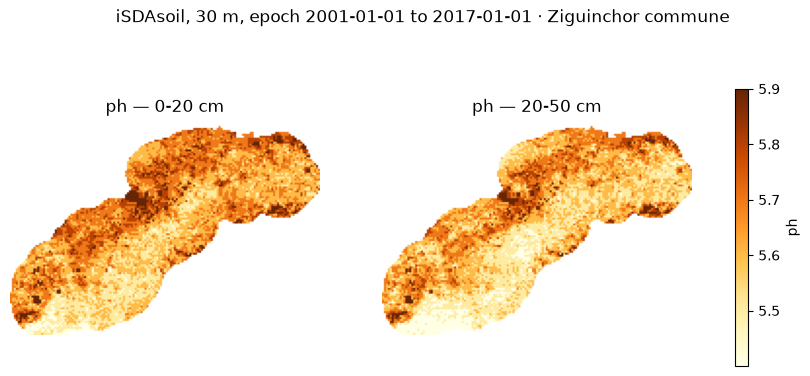

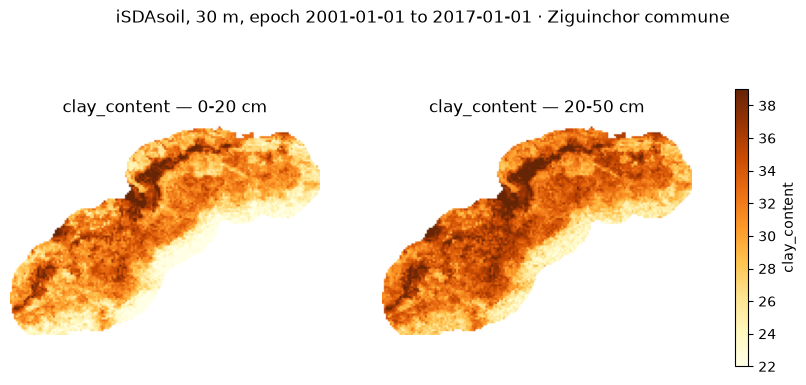

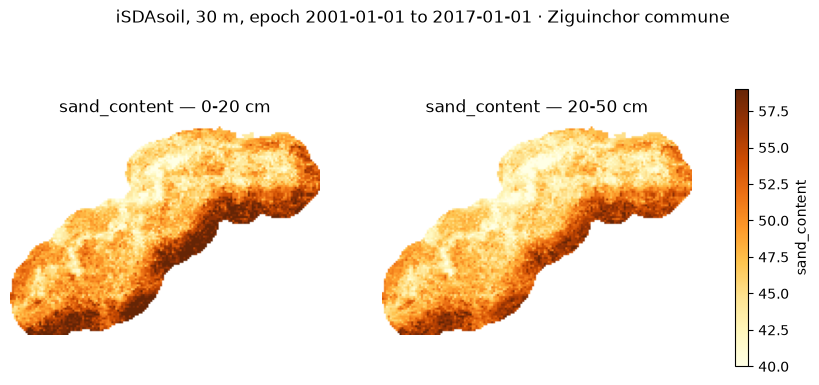

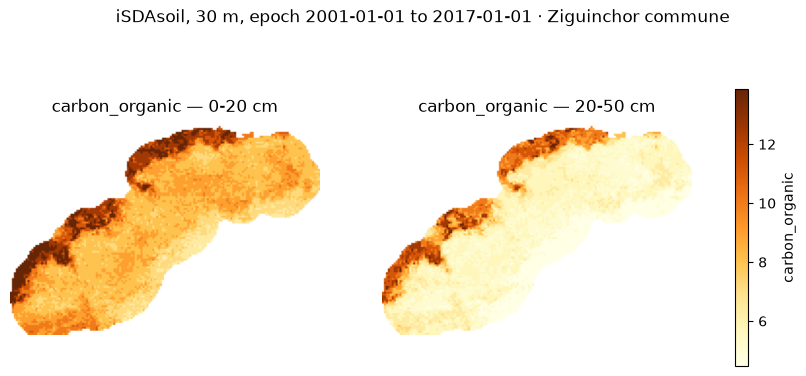

In [4]:
def plot_property(prop, cmap="YlOrBr"):
    raster = cache.get(prop) or read_isda(prop)
    cache[prop] = raster
    stack = np.concatenate([raster[d]["value"].ravel() for d in DEPTHS])
    vmin, vmax = np.nanpercentile(stack, 2), np.nanpercentile(stack, 98)

    tr = raster["transform"]
    rows_, cols_ = raster["shape"]
    extent = (tr.c, tr.c + tr.a * cols_, tr.f + tr.e * rows_, tr.f)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, depth in zip(axes, DEPTHS):
        ax.imshow(raster[depth]["value"], cmap=cmap, vmin=vmin, vmax=vmax, extent=extent)
        ax.set_title(f"{prop} — {depth}")
        ax.set_axis_off()
    fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin, vmax)),
                 ax=axes, shrink=0.8, label=prop)
    fig.suptitle("iSDAsoil, 30 m, epoch 2001-01-01 to 2017-01-01 · Ziguinchor commune")
    plt.show()


for prop in ["ph", "clay_content", "sand_content", "carbon_organic"]:
    plot_property(prop)

## Layer toggle: iSDAsoil 30 m vs SOTWIS 1:1M

Both panels are drawn in EPSG:4326 over the same AOI extent, so the 30 m prediction grid and the SOTER polygons line up on one frame. iSDAsoil is warped from its native EPSG:3857 to the AOI grid on the fly; SOTWIS is already geographic.

The two products answer different questions. iSDAsoil is a 30 m model prediction for 2001-01-01 to 2017-01-01. SOTWIS is a 2008 taxotransfer estimate attached to a 1:1M map unit, and only five of those units intersect this 32.8 km2 AOI. Agreement between them is not validation of either.


In [6]:
from pathlib import Path

import geopandas as gpd
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from affine import Affine
import io

from IPython.display import Image, display
from rasterio.enums import Resampling
from rasterio.features import geometry_mask
from rasterio.warp import reproject, transform_bounds
from rasterio.windows import from_bounds

# --- layers -----------------------------------------------------------------
AOI = gpd.read_file(aoi_path)
AOI_BOUNDS = AOI.total_bounds

SOTWIS = gpd.read_file(root / "data" / "interim" / "sotwis" / "ziguinchor_sotwis_d1_d2.geojson")
SOTWIS = SOTWIS.to_crs(4326)

# name, iSDAsoil property, SOTWIS column stem, colour map, fixed range (None = percentiles)
LAYERS = [
    ("pH", "ph", "ph_h2o", "RdYlBu_r", None),
    ("clay %", "clay_content", "clay_pct", "YlOrBr", None),
    ("sand %", "sand_content", "sand_pct", "YlOrBr", None),
    ("silt %", "silt_content", "silt_pct", "YlOrBr", None),
    ("organic carbon g/kg", "carbon_organic", "oc_gkg", "YlGn", None),
    ("CEC cmol(+)/kg", "cation_exchange_capacity", "cec_cmolkg", "PuBu", None),
    ("bulk density g/cm3", "bulk_density", "bulk_gcm3", "GnBu", None),
    ("ECe dS/m (SOTWIS only)", None, "ece_dsm", "OrRd", (0, 16)),
]
DEPTHS = ("0-20 cm", "subsoil (20-50 iSDA / 20-40 SOTWIS)")

_cache = {}


def isda_4326(prop, band_index):
    """iSDAsoil band as a 30 m array on the AOI's EPSG:4326 footprint."""
    key = ("isda", prop, band_index)
    if key in _cache:
        return _cache[key]

    back = BACK.get(prop, lambda x: x)
    with rasterio.open(S3.format(prop=prop)) as src:
        bounds = transform_bounds("EPSG:4326", src.crs, *AOI_BOUNDS)
        window = from_bounds(*bounds, transform=src.transform).round_offsets().round_lengths()
        sub = src.read(window=window)
        src_transform = src.window_transform(window)
        nodata = src.nodata

    res_deg = 30 / 111_320
    width = max(1, round((AOI_BOUNDS[2] - AOI_BOUNDS[0]) / res_deg))
    height = max(1, round((AOI_BOUNDS[3] - AOI_BOUNDS[1]) / res_deg))
    dst_transform = Affine(res_deg, 0, AOI_BOUNDS[0], 0, -res_deg, AOI_BOUNDS[3])

    band = sub[band_index].astype("float32")
    band[band == nodata] = np.nan
    warped = np.full((height, width), np.nan, dtype="float32")
    reproject(
        band, warped,
        src_transform=src_transform, src_crs=src.crs,
        dst_transform=dst_transform, dst_crs="EPSG:4326",
        src_nodata=np.nan, dst_nodata=np.nan,
        resampling=Resampling.nearest,
    )
    inside = ~geometry_mask(AOI.geometry, out_shape=warped.shape,
                            transform=dst_transform, all_touched=True)
    values = np.where(inside, back(warped), np.nan)
    _cache[key] = (values, dst_transform)
    return values, dst_transform


def draw_isda(ax, prop, depth_index, cmap, fixed):
    values, tr = isda_4326(prop, depth_index)
    h, w = values.shape
    extent = (tr.c, tr.c + tr.a * w, tr.f + tr.e * h, tr.f)
    if fixed:
        vmin, vmax = fixed
    else:
        vmin, vmax = np.nanpercentile(values, 2), np.nanpercentile(values, 98)
    image = ax.imshow(values, extent=extent, cmap=cmap, vmin=vmin, vmax=vmax)
    AOI.boundary.plot(ax=ax, color="black", linewidth=0.8)
    ax.set_xlim(AOI_BOUNDS[0], AOI_BOUNDS[2])
    ax.set_ylim(AOI_BOUNDS[1], AOI_BOUNDS[3])
    ax.set_aspect("equal")
    ax.set_axis_off()
    return image


def draw_sotwis(ax, stem, depth_suffix, cmap, fixed):
    column = f"{stem}_{depth_suffix}"
    frame = SOTWIS
    if fixed:
        vmin, vmax = fixed
    else:
        vmin, vmax = np.nanpercentile(frame[column].dropna(), 2), np.nanpercentile(frame[column].dropna(), 98)
    if vmax == vmin:
        vmax = vmin + 1
    frame.plot(column=column, ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,
               edgecolor="black", linewidth=0.6, missing_kwds={"color": "0.9"})
    AOI.boundary.plot(ax=ax, color="#1f5c3a", linewidth=1.2, linestyle="--")
    ax.set_xlim(AOI_BOUNDS[0], AOI_BOUNDS[2])
    ax.set_ylim(AOI_BOUNDS[1], AOI_BOUNDS[3])
    ax.set_aspect("equal")
    ax.set_axis_off()
    # geopandas draws straight onto the axes, so hand back a mappable for the colourbar.
    return plt.cm.ScalarMappable(cmap=plt.get_cmap(cmap), norm=plt.Normalize(vmin, vmax))


view = widgets.RadioButtons(
    options=["side by side", "iSDAsoil only", "SOTWIS only"],
    value="side by side", description="view", layout=widgets.Layout(width="320px"),
)
property_select = widgets.Dropdown(
    options=[(name, i) for i, (name, *_rest) in enumerate(LAYERS)],
    value=0, description="property", layout=widgets.Layout(width="320px"),
)
depth_select = widgets.Dropdown(
    options=list(DEPTHS), value=DEPTHS[0], description="depth",
    layout=widgets.Layout(width="320px"),
)
note = widgets.HTML()

out = widgets.Output()


def render(_=None):
    name, isda_prop, stem, cmap, fixed = LAYERS[property_select.value]
    depth_index = DEPTHS.index(depth_select.value)
    sotwis_depth = "0-20" if depth_index == 0 else "20-40"

    with out:
        out.clear_output(wait=True)
        mode = view.value
        if isda_prop is None:
            # iSDAsoil has no ECe layer; fall back to SOTWIS instead of drawing a blank panel.
            mode = "SOTWIS only"
        views = 2 if mode == "side by side" else 1
        both = mode == "side by side"
        fig, axes = plt.subplots(1, views, figsize=(7 * views, 6.5), squeeze=False)
        axes = axes[0]

        images = []
        if mode != "SOTWIS only":
            images.append(draw_isda(axes[0], isda_prop, depth_index, cmap, fixed))
            axes[0].set_title(f"iSDAsoil 30 m — {name}, {DEPTHS[depth_index].split(' (')[0]}")
        if mode != "iSDAsoil only":
            ax_s = axes[1] if both else axes[0]
            images.append(draw_sotwis(ax_s, stem, sotwis_depth, cmap, fixed))
            ax_s.set_title(f"SOTWIS 1:1M SOTER units — {name}, {sotwis_depth} cm")

        missing = "<b>iSDAsoil has no ECe layer</b>, SOTWIS shown alone. " if isda_prop is None else ""
        note.value = missing + (
            "iSDAsoil: model prediction, epoch 2001-01-01 to 2017-01-01, CC BY 4.0. "
            "SOTWIS: taxotransfer estimate for a 1:1M map unit, 2008, ISRIC copyright, "
            "non-commercial use only — not for redistribution. Depths differ: iSDAsoil subsoil is "
            "20-50 cm, SOTWIS is 20-40 cm."
        )
        for image, ax in zip(images, axes):
            fig.colorbar(image, ax=ax, shrink=0.75)
        fig.suptitle(f"{name} · Ziguinchor commune pilot AOI")
        fig.tight_layout()
        buffer = io.BytesIO()
        fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
        plt.close(fig)
        # Render the PNG directly: fig.show() and display(fig) both stall nbconvert
        # because of the inline backend's post-execute hook inside a widget Output.
        display(Image(data=buffer.getvalue()))


for w in (view, property_select, depth_select):
    w.observe(render, names="value")

display(widgets.VBox([widgets.HBox([view, widgets.VBox([property_select, depth_select])]), note, out]))
render()
